In [604]:
import sys
import inspect

sys.path.insert(0, "/content/Epiaware/src")

import epiaware.evaluation.pipeline as pipeline

print("Pipeline location:")
print(pipeline.__file__)

print("\nAvailable functions:")
for name, function in inspect.getmembers(pipeline, inspect.isfunction):
    print(name, inspect.signature(function))

print("\nEVALUATE_ENSEMBLE SOURCE:")
print(inspect.getsource(pipeline.evaluate_ensemble))

Pipeline location:
/content/Epiaware/src/epiaware/evaluation/pipeline.py

Available functions:
calculate_aurc (risk)
calculate_error_detection_metrics (error_labels, uncertainty_scores)
evaluate_ensemble (probabilities, ground_truth, experiment_name='experiment', corruption_type='clean', severity=None)
expected_calibration_error (confidences, correctness, num_bins=15)
get_ensemble_probabilities (probabilities)
get_error_labels (predictions, ground_truth)
get_predictions (probabilities)
jensen_shannon_divergence (probabilities)
predictive_entropy (probabilities)
risk_coverage_curve (error_labels, uncertainty_scores)
save_evaluation_results (summary, sample_results, output_directory='results')
variation_ratio (predictions)

EVALUATE_ENSEMBLE SOURCE:
def evaluate_ensemble(
    probabilities,
    ground_truth,
    experiment_name="experiment",
    corruption_type="clean",
    severity=None
):
    """
    Evaluate ensemble predictions using all implemented metrics.

    Args:
        probab

In [605]:
import inspect
from epiaware.evaluation.pipeline import save_evaluation_results

print(inspect.getsource(save_evaluation_results))

def save_evaluation_results(
    summary,
    sample_results,
    output_directory="results"
):
    """Save summary and sample-level results as CSV files."""

    output_directory = Path(output_directory)
    output_directory.mkdir(parents=True, exist_ok=True)

    summary_path = output_directory / "evaluation_summary.csv"
    samples_path = output_directory / "sample_results.csv"

    summary_dataframe = pd.DataFrame([summary])

    summary_dataframe.to_csv(
        summary_path,
        index=False
    )

    sample_results.to_csv(
        samples_path,
        index=False
    )

    return summary_path, samples_path



In [607]:
# Find missing values in experiment summary

numeric_columns = summary_df.select_dtypes(
    include=[np.number]
).columns

missing_values = summary_df[numeric_columns].isna().sum()

print("Columns containing NaN:")
print(missing_values[missing_values > 0])

print("\nAffected experiment conditions:")
for column in numeric_columns:
    if summary_df[column].isna().any():
        print(f"\n{column}")
        display(
            summary_df.loc[
                summary_df[column].isna(),
                ["corruption_type", "severity"]
            ]
        )

Columns containing NaN:
severity    1
dtype: int64

Affected experiment conditions:

severity


,corruption_type,severity
0,clean,NaN


Evaluation module: /content/Epiaware/src/epiaware/evaluation/pipeline.py
Corruption module: /content/Epiaware/src/epiaware/data/corruptions.py
Device: cpu
gaussian_noise PASSED
gaussian_blur PASSED
rotation PASSED

Synthetic labels created: 1000
Total conditions: 16
Completed 1/16: clean None
Completed 2/16: gaussian_noise 1
Completed 3/16: gaussian_noise 2
Completed 4/16: gaussian_noise 3
Completed 5/16: gaussian_noise 4
Completed 6/16: gaussian_noise 5
Completed 7/16: gaussian_blur 1
Completed 8/16: gaussian_blur 2
Completed 9/16: gaussian_blur 3
Completed 10/16: gaussian_blur 4
Completed 11/16: gaussian_blur 5
Completed 12/16: rotation 1
Completed 13/16: rotation 2
Completed 14/16: rotation 3
Completed 15/16: rotation 4
Completed 16/16: rotation 5

SUMMARY RESULTS


,experiment_name,corruption_type,severity,number_of_samples,number_of_models,ensemble_accuracy,model_1_accuracy,model_2_accuracy,model_3_accuracy,ensemble_ece,...,variation_ratio_auroc,variation_ratio_auprc,variation_ratio_aurc,jsd_auroc,jsd_auprc,jsd_aurc,model_1_mean_entropy,model_2_mean_entropy,model_3_mean_entropy,mean_member_entropy
0,Synthetic Validation,clean,NaN,1000,3,0.106,0.083,0.097,0.093,0.106485,...,0.493130,0.892688,0.904525,0.489606,0.898716,0.904674,1.925854,1.932134,1.923231,1.927073
1,Synthetic Validation,gaussian_noise,1.0,1000,3,0.080,0.108,0.100,0.084,0.135389,...,0.520992,0.923140,0.915701,0.544130,0.932499,0.907401,1.924016,1.934724,1.920267,1.926336
2,Synthetic Validation,gaussian_noise,2.0,1000,3,0.093,0.100,0.093,0.083,0.119178,...,0.477665,0.903220,0.919644,0.469419,0.900497,0.920553,1.923871,1.926779,1.921023,1.923891
3,Synthetic Validation,gaussian_noise,3.0,1000,3,0.110,0.095,0.128,0.100,0.103720,...,0.458212,0.881821,0.909900,0.502022,0.900483,0.886812,1.926562,1.910568,1.938187,1.925106
4,Synthetic Validation,gaussian_noise,4.0,1000,3,0.109,0.120,0.092,0.107,0.103056,...,0.466917,0.884572,0.900022,0.534180,0.901857,0.878068,1.927688,1.925141,1.919431,1.924087
5,Synthetic Validation,gaussian_noise,5.0,1000,3,0.094,0.112,0.098,0.096,0.123364,...,0.523989,0.910154,0.893956,0.492027,0.907565,0.901543,1.908175,1.922639,1.924556,1.918457
6,Synthetic Validation,gaussian_blur,1.0,1000,3,0.089,0.090,0.098,0.088,0.125825,...,0.495196,0.910227,0.917926,0.491459,0.911687,0.912003,1.929904,1.924414,1.921002,1.925107
7,Synthetic Validation,gaussian_blur,2.0,1000,3,0.096,0.108,0.086,0.091,0.117939,...,0.501423,0.904252,0.902790,0.497742,0.903901,0.903660,1.922202,1.926273,1.933502,1.927326
8,Synthetic Validation,gaussian_blur,3.0,1000,3,0.107,0.119,0.100,0.106,0.106248,...,0.535191,0.899923,0.889423,0.528126,0.902183,0.890745,1.928344,1.930617,1.912500,1.923820
9,Synthetic Validation,gaussian_blur,4.0,1000,3,0.110,0.104,0.108,0.100,0.103336,...,0.514995,0.892963,0.882987,0.467038,0.884523,0.889632,1.922059,1.929096,1.933370,1.928175



SAMPLE RESULTS


,ground_truth,prediction,correct,error,ensemble_confidence,ensemble_entropy,variation_ratio,jsd,model_1_entropy,model_2_entropy,model_3_entropy,mean_member_entropy,corruption_type,severity
0,6,8,False,1,0.142969,2.230296,0.666667,0.206973,2.001165,2.064561,2.004243,2.023323,clean,None
1,3,4,False,1,0.230525,2.170483,0.333333,0.160017,1.889065,2.052310,2.090024,2.010467,clean,None
2,7,4,False,1,0.196822,2.226464,0.666667,0.160569,2.173467,1.918133,2.106087,2.065896,clean,None
3,4,8,False,1,0.236407,2.131154,0.666667,0.277163,1.585548,2.018543,1.957882,1.853991,clean,None
4,6,6,True,0,0.194586,2.107305,0.666667,0.136956,1.809831,2.029168,2.072047,1.970349,clean,None



Saved summary: /content/Epiaware/results/synthetic_validation/evaluation_summary.csv
Saved samples: /content/Epiaware/results/synthetic_validation/sample_results.csv


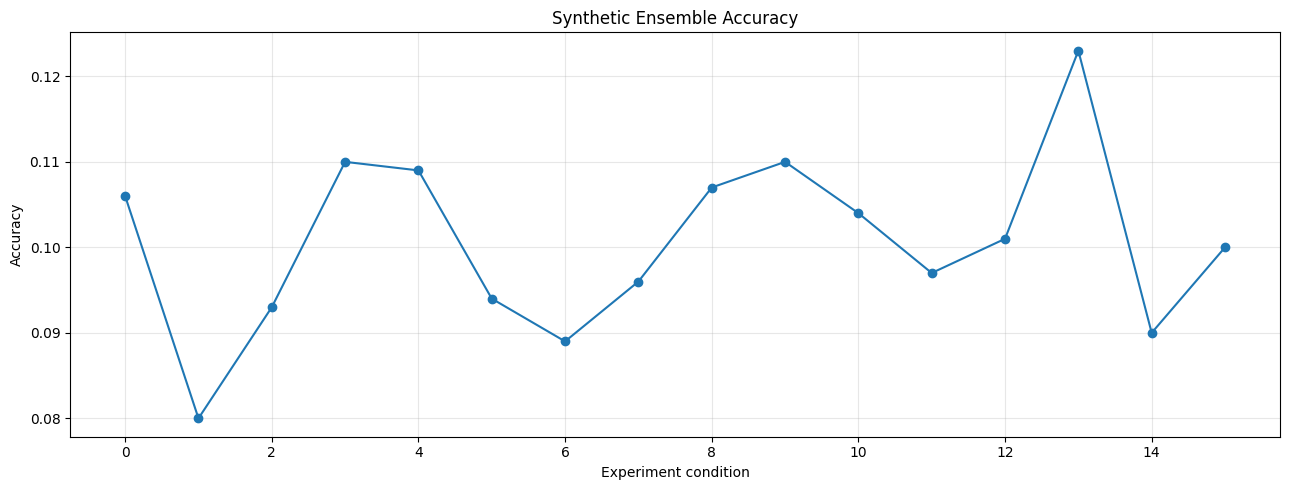

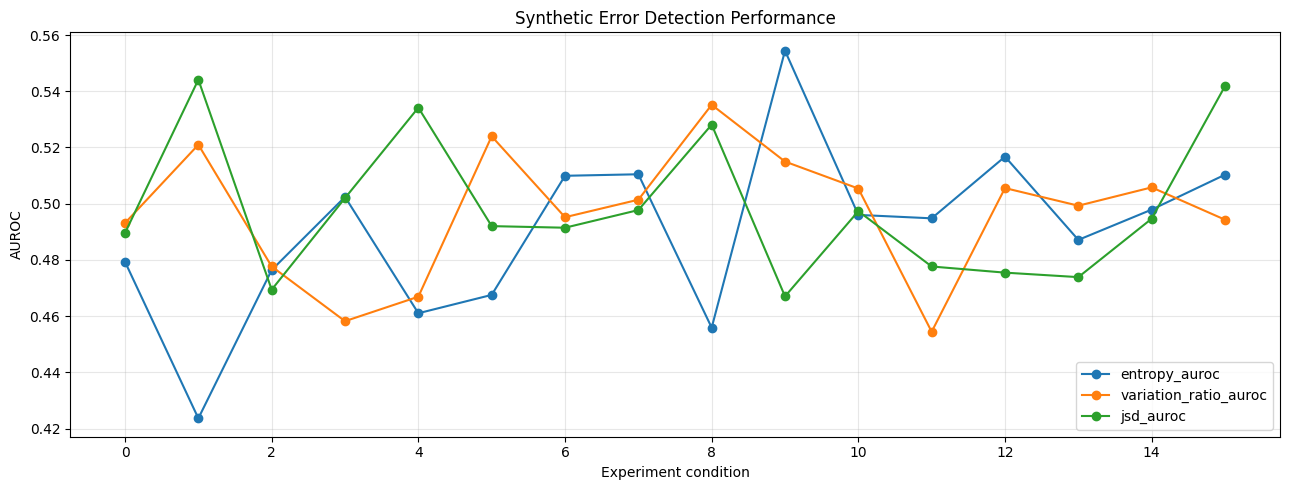

All numeric evaluation metrics are valid.

EPIAWARE PIPELINE VALIDATION PASSED
Shared corruption functions: PASSED
Stable logits conversion: PASSED
Existing evaluation metrics: PASSED
Individual member entropy: PASSED
Ensemble entropy: PASSED
Error detection: PASSED
Calibration: PASSED
Selective prediction: PASSED
16 experiment conditions: PASSED
Cumulative CSV exports: PASSED

IMPORTANT: All predictions in this run are synthetic.
Real CIFAR-10/ResNet-18 experiments are not yet performed.


In [608]:

# ================================================================
# EPIAWARE - COMPLETE UNCERTAINTY EVALUATION
# Synthetic pipeline validation - single cell
# ================================================================

import os
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ------------------------------------------------
# 1. REPOSITORY SETUP
# ------------------------------------------------

REPO_PATH = Path("/content/Epiaware")
SRC_PATH = REPO_PATH / "src"

if not SRC_PATH.exists():
    raise FileNotFoundError("Epiaware/src folder not found.")

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

import epiaware.evaluation.pipeline as evaluation
from epiaware.data import corruptions

print("Evaluation module:", evaluation.__file__)
print("Corruption module:", corruptions.__file__)

# ------------------------------------------------
# 2. REPRODUCIBILITY
# ------------------------------------------------

RANDOM_SEED = 42
ENSEMBLE_SIZE = 3
NUM_CLASSES = 10
NUM_SAMPLES = 1000

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

OUTPUT_DIR = REPO_PATH / "results" / "synthetic_validation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", device)

# ------------------------------------------------
# 3. SHARED CORRUPTION FUNCTIONS
# ------------------------------------------------

CORRUPTION_FUNCTIONS = {
    "gaussian_noise": corruptions.gaussian_noise,
    "gaussian_blur": corruptions.gaussian_blur,
    "rotation": corruptions.rotation
}

def apply_corruption(images, corruption_type, severity):

    if corruption_type not in CORRUPTION_FUNCTIONS:
        raise ValueError("Unknown corruption type.")

    if not 1 <= severity <= 5:
        raise ValueError("Severity must be between 1 and 5.")

    corrupted_images = []

    for image_index, image in enumerate(images):

        image_array = (
            image.detach()
            .cpu()
            .permute(1, 2, 0)
            .numpy()
        )

        image_array = np.clip(
            np.rint(image_array * 255),
            0,
            255
        ).astype(np.uint8)

        if corruption_type == "gaussian_noise":
            corrupted_image = corruptions.gaussian_noise(
                image_array,
                severity,
                seed=RANDOM_SEED + image_index
            )
        else:
            corrupted_image = CORRUPTION_FUNCTIONS[
                corruption_type
            ](image_array, severity)

        corrupted_tensor = torch.from_numpy(
            corrupted_image.copy()
        )

        corrupted_tensor = (
            corrupted_tensor.permute(2, 0, 1).float() / 255.0
        )

        corrupted_images.append(corrupted_tensor)

    return torch.stack(corrupted_images)

# ------------------------------------------------
# 4. TEST CORRUPTION IMPLEMENTATION
# ------------------------------------------------

dummy_images = torch.rand(8, 3, 32, 32)

for corruption_type in CORRUPTION_FUNCTIONS:

    corrupted_images = apply_corruption(
        dummy_images,
        corruption_type,
        severity=3
    )

    assert corrupted_images.shape == dummy_images.shape
    assert torch.isfinite(corrupted_images).all()
    assert torch.all(corrupted_images >= 0)
    assert torch.all(corrupted_images <= 1)

    print(corruption_type, "PASSED")

# ------------------------------------------------
# 5. STABLE SOFTMAX
# ------------------------------------------------

def convert_logits_to_probabilities(logits):

    logits = np.asarray(logits, dtype=np.float64)

    if logits.ndim != 3:
        raise ValueError(
            "Logits must have shape (models, samples, classes)."
        )

    if not np.isfinite(logits).all():
        raise ValueError("Logits contain non-finite values.")

    shifted_logits = logits - np.max(
        logits,
        axis=2,
        keepdims=True
    )

    exponential_values = np.exp(shifted_logits)

    probabilities = exponential_values / np.sum(
        exponential_values,
        axis=2,
        keepdims=True
    )

    return probabilities

# ------------------------------------------------
# 6. INDIVIDUAL MEMBER ENTROPY
# ------------------------------------------------

def calculate_member_entropy(probabilities):

    probabilities = np.asarray(probabilities)

    safe_probabilities = np.clip(
        probabilities,
        1e-12,
        1.0
    )

    return -np.sum(
        safe_probabilities * np.log(safe_probabilities),
        axis=2
    )

# ------------------------------------------------
# 7. CREATE SYNTHETIC TEST LABELS
# ------------------------------------------------

ground_truth = np.random.randint(
    0,
    NUM_CLASSES,
    size=NUM_SAMPLES
)

print("\nSynthetic labels created:", len(ground_truth))

# ------------------------------------------------
# 8. EXPERIMENT CONFIGURATIONS
# ------------------------------------------------

experiment_configs = [
    {
        "corruption": "clean",
        "severity": None
    }
]

for corruption_type in CORRUPTION_FUNCTIONS:

    for severity in range(1, 6):

        experiment_configs.append({
            "corruption": corruption_type,
            "severity": severity
        })

print("Total conditions:", len(experiment_configs))

# ------------------------------------------------
# 9. RUN SYNTHETIC EVALUATION
# ------------------------------------------------

all_summaries = []
all_sample_results = []

for condition_index, config in enumerate(experiment_configs):

    corruption_type = config["corruption"]
    severity = config["severity"]

    # Synthetic logits are used only to validate
    # the evaluation pipeline.

    synthetic_logits = np.random.randn(
        ENSEMBLE_SIZE,
        NUM_SAMPLES,
        NUM_CLASSES
    )

    probabilities = convert_logits_to_probabilities(
        synthetic_logits
    )

    # Existing evaluation package.

    summary, sample_results = evaluation.evaluate_ensemble(
        probabilities,
        ground_truth,
        experiment_name="Synthetic Validation",
        corruption_type=corruption_type,
        severity=severity
    )

    # Individual-member predictive entropy.

    member_entropies = calculate_member_entropy(
        probabilities
    )

    for model_index in range(ENSEMBLE_SIZE):

        column_name = f"model_{model_index + 1}_entropy"

        sample_results[column_name] = (
            member_entropies[model_index]
        )

        summary[f"model_{model_index + 1}_mean_entropy"] = (
            float(np.mean(member_entropies[model_index]))
        )

    sample_results["mean_member_entropy"] = np.mean(
        member_entropies,
        axis=0
    )

    summary["mean_member_entropy"] = float(
        np.mean(member_entropies)
    )

    sample_results["corruption_type"] = corruption_type
    sample_results["severity"] = severity

    all_summaries.append(summary)
    all_sample_results.append(sample_results)

    print(
        f"Completed {condition_index + 1}/16:",
        corruption_type,
        severity
    )

# ------------------------------------------------
# 10. COMBINE ALL EXPERIMENT RESULTS
# ------------------------------------------------

summary_df = pd.DataFrame(all_summaries)

sample_df = pd.concat(
    all_sample_results,
    ignore_index=True
)

print("\nSUMMARY RESULTS")
display(summary_df)

print("\nSAMPLE RESULTS")
display(sample_df.head())

# ------------------------------------------------
# 11. SAVE CUMULATIVE CSV FILES
# ------------------------------------------------

summary_path = OUTPUT_DIR / "evaluation_summary.csv"
sample_path = OUTPUT_DIR / "sample_results.csv"

summary_df.to_csv(
    summary_path,
    index=False
)

sample_df.to_csv(
    sample_path,
    index=False
)

print("\nSaved summary:", summary_path)
print("Saved samples:", sample_path)

# ------------------------------------------------
# 12. VISUALIZE ENSEMBLE ACCURACY
# ------------------------------------------------

plt.figure(figsize=(13, 5))

plt.plot(
    range(len(summary_df)),
    summary_df["ensemble_accuracy"],
    marker="o"
)

plt.xlabel("Experiment condition")
plt.ylabel("Accuracy")
plt.title("Synthetic Ensemble Accuracy")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 13. VISUALIZE ERROR DETECTION AUROC
# ------------------------------------------------

auroc_columns = [
    "entropy_auroc",
    "variation_ratio_auroc",
    "jsd_auroc"
]

plt.figure(figsize=(13, 5))

for column in auroc_columns:

    plt.plot(
        range(len(summary_df)),
        summary_df[column],
        marker="o",
        label=column
    )

plt.xlabel("Experiment condition")
plt.ylabel("AUROC")
plt.title("Synthetic Error Detection Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 14. VALIDATION
# ------------------------------------------------

assert len(summary_df) == 16
assert len(sample_df) == 16 * NUM_SAMPLES

assert all(
    f"model_{index}_entropy" in sample_df.columns
    for index in range(1, ENSEMBLE_SIZE + 1)
)

assert "ensemble_entropy" in sample_df.columns
assert "ensemble_ece" in summary_df.columns
assert "entropy_auroc" in summary_df.columns
assert "entropy_auprc" in summary_df.columns
assert "entropy_aurc" in summary_df.columns

# All numeric metrics must be valid.
# Severity is excluded because clean experiments have no severity.

numeric_columns = summary_df.select_dtypes(
    include=[np.number]
).columns.tolist()

numeric_columns.remove("severity")

assert summary_df[numeric_columns].notna().all().all()

print("All numeric evaluation metrics are valid.")

print("\n" + "=" * 60)
print("EPIAWARE PIPELINE VALIDATION PASSED")
print("=" * 60)

print("Shared corruption functions: PASSED")
print("Stable logits conversion: PASSED")
print("Existing evaluation metrics: PASSED")
print("Individual member entropy: PASSED")
print("Ensemble entropy: PASSED")
print("Error detection: PASSED")
print("Calibration: PASSED")
print("Selective prediction: PASSED")
print("16 experiment conditions: PASSED")
print("Cumulative CSV exports: PASSED")

print("\nIMPORTANT: All predictions in this run are synthetic.")
print("Real CIFAR-10/ResNet-18 experiments are not yet performed.")


In [609]:
%cd /content/Epiaware

!git branch --show-current
!git status --short
!git remote -v
!git log -1 --oneline

/content/Epiaware
feature/uncertainty-evaluation
origin	https://github.com/rhea3006/Epiaware.git (fetch)
origin	https://github.com/rhea3006/Epiaware.git (push)
3faffc5 (HEAD -> feature/uncertainty-evaluation, origin/feature/uncertainty-evaluation) Add evaluation package initializer


In [610]:
%cd /content/Epiaware

!git ls-files "*EpiAware*"
!ls -lah notebooks/
!git diff -- notebooks/EpiAware_Uncertainty_Evaluation.ipynb

/content/Epiaware
notebooks/EpiAware_Uncertainty_Evaluation.ipynb
total 512K
drwxr-xr-x  2 root root 4.0K Nov 16 10:33 .
drwxr-xr-x 10 root root 4.0K Nov 16 10:56 ..
-rw-r--r--  1 root root 501K Nov 16 10:33 EpiAware_Uncertainty_Evaluation.ipynb
